# Implement Composite Analysis

## Import package

In [14]:
import h5py
import numpy as np

from typing import cast
from pathlib import Path

from matplotlib import pyplot as plt

style_path = Path("/home/b11209013/Kuang-python/v0.1.0_Analysis/scientific.mplstyle")

plt.style.use(style_path)

## Load data

### Configuration

In [15]:
data_path: Path = Path("/work/b11209013/Kuang-python/v0.1.0/two-way/Eastward")
EXPS: list[str] = ["NoRad", "Rad"]
FILES: list[str] = ["2026-10-28-07-25-19-242016551-4092283", "2026-10-23-22-49-17-016775038-2530645"]

# Process only the first entry for now. Use EXPS[:] after updating the Rad path.
active_exps: list[str] = EXPS[:1]
run_paths: dict[str, Path] = {exp: data_path / exp / run for exp, run in zip(EXPS, FILES)}


### Loading

In [16]:
# Load Fourier State
with h5py.File(run_paths["NoRad"] / "GalerkinState.h5", "r") as f:
    x: np.ndarray = cast(h5py.Dataset, f["x"])[:]
    z: np.ndarray = cast(h5py.Dataset, f["z"])[:]
    t: np.ndarray = cast(h5py.Dataset, f["time"])[:]

    data: dict[str, np.ndarray] = {
        key: cast(h5py.Dataset, f[key])[...]
        for key in ["w1", "w2", "T1", "T2", "J1", "J2"]
    } # shape: (ensemble, time, zonal, level)

nens, nt, nx, nz = data["w1"].shape

## Roll column heating maximum to the center

### Use convective heating to calculate column heating

In [17]:
# combining J1 and J2 to form Qc
Qc: np.ndarray = data["J1"] + data["J2"]

# vertically integrate Qc
Qc_column: np.ndarray = np.trapz(Qc, z, axis=-1) / np.trapz(np.ones_like(z), z, axis=-1)

### Select the composite period

Use the reference notebook's heating-centered composite: exclude the first
20 days, shift each ensemble/time snapshot so its column-heating maximum is
at the center, then average over the retained times and members. The loading
and trapezoidal column-heating calculation above are unchanged. Here arrays
have axes `(ensemble, time, x, z)`, and the centering proxy is the existing
`Qc_column` (the vertically integrated heating divided by the column depth).

Set `skip_days = 0` to include all loaded times. The time coordinate is in days.

In [18]:
skip_days: float = 20.0
composite_time_indices = np.flatnonzero(t >= skip_days)
if nens == 0 or composite_time_indices.size == 0:
    raise ValueError("The composite requires at least one member and one retained time.")
print(f"Compositing {nens} members and {composite_time_indices.size} times "
      f"from {t[composite_time_indices[0]]:g} to {t[composite_time_indices[-1]]:g} days.")

Compositing 104 members and 20 times from 20.375 to 39.375 days.


### Roll each heating maximum to the center of the domain

As in the reference, `nanargmax` selects the first maximum when periodic
peaks tie. That selected peak is centered; other equal maxima can remain.

In [19]:
# Keep the existing center at x closest to zero (NX // 2 on this grid).
x_center_idx: np.intp = np.argmin(np.abs(x))

# Each retained (ensemble, time) pair gets its own shift.
Qc_column_selected = Qc_column[:, composite_time_indices, :]
if np.any(np.all(np.isnan(Qc_column_selected), axis=-1)):
    raise ValueError("Cannot locate a heating maximum in an all-NaN column profile.")
Qc_column_max = np.nanargmax(Qc_column_selected, axis=-1)
shifts: np.ndarray = x_center_idx - Qc_column_max  # (ensemble, retained time)

# Preserve Qc_column so this cell can be rerun without shifting the input again.
Qc_column_rolled = np.empty_like(Qc_column_selected)
for ne in range(nens):
    for jt in range(composite_time_indices.size):
        Qc_column_rolled[ne, jt] = np.roll(
            Qc_column_selected[ne, jt], int(shifts[ne, jt]), axis=0,
        )

Qc_column_composite = np.nanmean(Qc_column_rolled, axis=(0, 1))  # (x,)

### Apply the same shifts to all fields and average

The reference rolls every field using the total-heating maximum, then applies
`np.nanmean` over time and ensemble. The helper below computes the same mean
one snapshot at a time, avoiding a full extra copy of each four-dimensional
field. Counts are tracked at each grid point to preserve `nanmean` behavior.
Modal fields and combined `J`, `w`, and `T` are retained in `norad_composite`;
each result has shape `(x, z)`. Combined fields are added **before** averaging.

In [20]:
def heating_centered_composite(field, shifts, time_indices, second_field=None):
    """Composite (ensemble, time, x, z) data using heating-based x shifts."""
    if field.ndim != 4:
        raise ValueError("Expected field axes (ensemble, time, x, z).")
    if shifts.shape != (field.shape[0], len(time_indices)):
        raise ValueError("Provide one shift for each retained ensemble/time pair.")
    if second_field is not None and second_field.shape != field.shape:
        raise ValueError("The two modal fields must have matching shapes.")
    total = np.zeros(field.shape[2:], dtype=np.result_type(field.dtype, np.float64))
    count = np.zeros(field.shape[2:], dtype=np.int64)
    for ne in range(field.shape[0]):
        for jt, it in enumerate(time_indices):
            snapshot = field[ne, it]
            if second_field is not None:
                snapshot = snapshot + second_field[ne, it]
            centered = np.roll(snapshot, int(shifts[ne, jt]), axis=0)
            valid = ~np.isnan(centered)
            total += np.where(valid, centered, 0)
            count += valid
    composite = np.full(total.shape, np.nan, dtype=total.dtype)
    np.divide(total, count, out=composite, where=count > 0)
    return composite


norad_composite: dict[str, np.ndarray] = {
    key: heating_centered_composite(values, shifts, composite_time_indices)
    for key, values in data.items()
}
norad_composite["J"] = heating_centered_composite(Qc, shifts, composite_time_indices)
for key in ("w", "T"):
    norad_composite[key] = heating_centered_composite(
        data[f"{key}1"], shifts, composite_time_indices,
        second_field=data[f"{key}2"],
    )

# Coordinates relative to the heating center, for plots or subsequent analysis.
x_relative = x - x[x_center_idx]
print("Composite field shapes:", {key: value.shape for key, value in norad_composite.items()})

Composite field shapes: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}


### Inspect the centered column-heating profiles

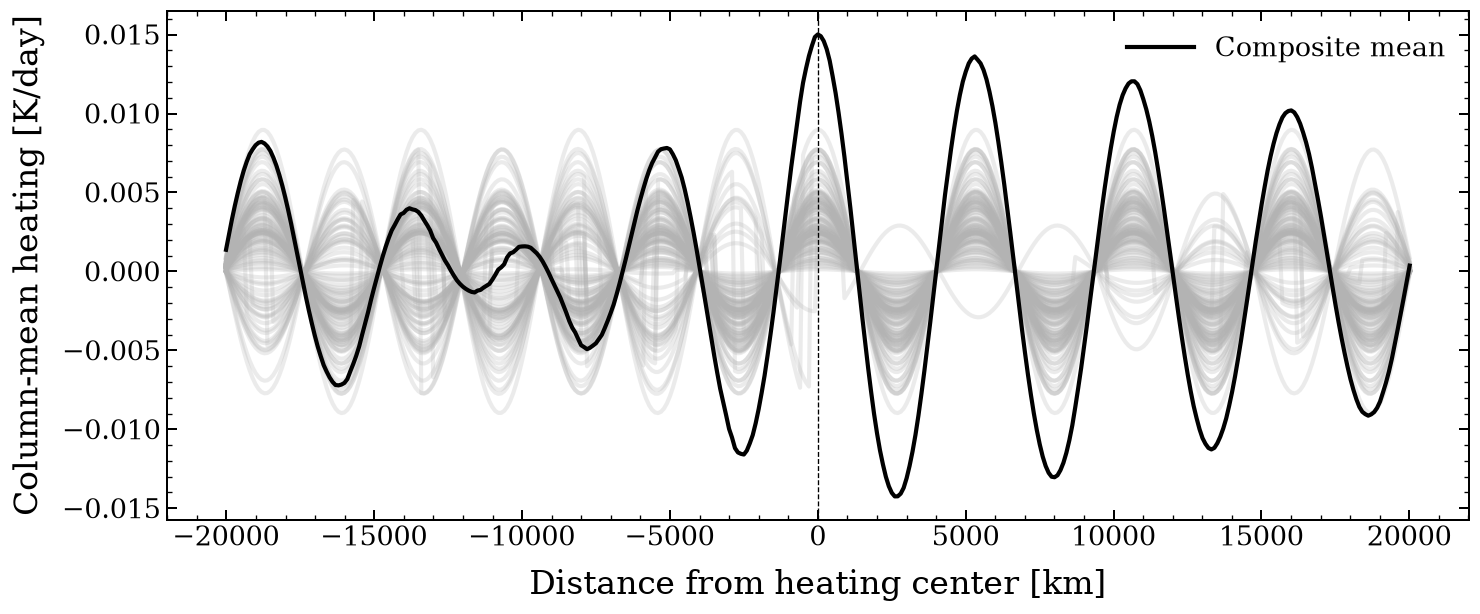

In [21]:
fig, ax = plt.subplots()
# Show every member at the first retained time and the full composite mean.
ax.plot(x_relative / 1000.0, Qc_column_rolled[:, 0, :].T, color="0.7", alpha=0.25)
ax.plot(x_relative / 1000.0, Qc_column_composite, color="k", label="Composite mean")
ax.axvline(0, color="k", linestyle="--", linewidth=0.8)
ax.set(xlabel="Distance from heating center [km]", ylabel="Column-mean heating [K/day]")
ax.legend()
plt.show()
plt.close(fig)

## Visualize the composite fields

Use the reference's relative-longitude coordinates and display the central
±50°. Heating is shaded; the total vertical velocity and temperature are
contoured. Transpose `(x, z)` composites only for plotting.

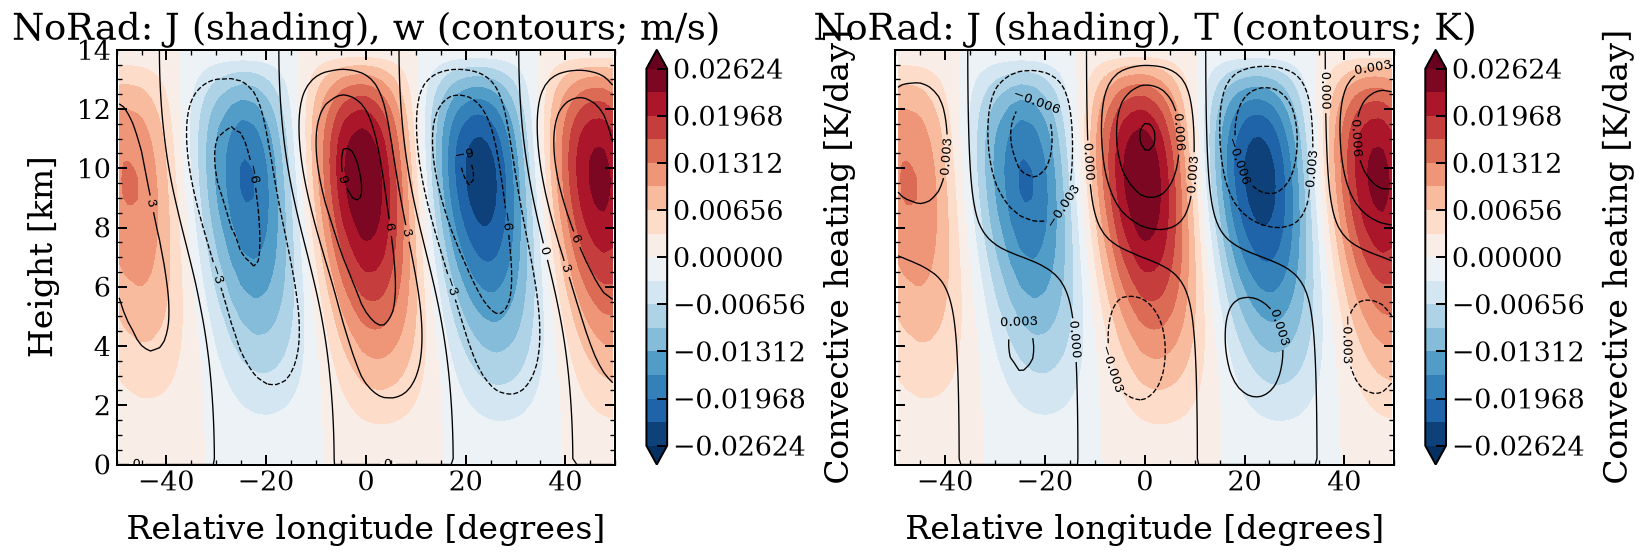

In [22]:
metres_per_degree = 2 * np.pi * 6.371e6 / 360.0
x_relative_degrees = x_relative / metres_per_degree
height_km = z / 1000.0
visible = np.abs(x_relative_degrees) <= 50.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
heating = norad_composite["J"][visible, :].T
heating_limit = float(np.nanmax(np.abs(heating)))
if heating_limit == 0:
    heating_limit = 1.0
heating_levels = np.linspace(-heating_limit, heating_limit, 17)
for ax, field_name, units in zip(axes, ("w", "T"), ("m/s", "K")):
    shading = ax.contourf(
        x_relative_degrees[visible], height_km, heating,
        levels=heating_levels, cmap="RdBu_r", extend="both",
    )
    contours = ax.contour(
        x_relative_degrees[visible], height_km,
        norad_composite[field_name][visible, :].T,
        levels=6, colors="k", linewidths=0.8,
    )
    ax.clabel(contours, inline=True, fontsize=8)
    ax.set(xlabel="Relative longitude [degrees]", xlim=(-50, 50),
           title=f"NoRad: J (shading), {field_name} (contours; {units})")
    fig.colorbar(shading, ax=ax, label="Convective heating [K/day]")
axes[0].set_ylabel("Height [km]")
fig.tight_layout()
plt.show()
plt.close(fig)